Epoch 1/3
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.9346 - loss: 0.2293 - val_accuracy: 0.9708 - val_loss: 0.0928
Epoch 2/3
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9753 - loss: 0.0842 - val_accuracy: 0.9783 - val_loss: 0.0662
Epoch 3/3
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9818 - loss: 0.0633 - val_accuracy: 0.9792 - val_loss: 0.0585


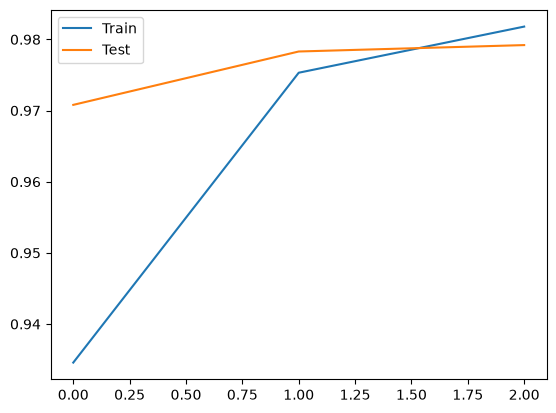

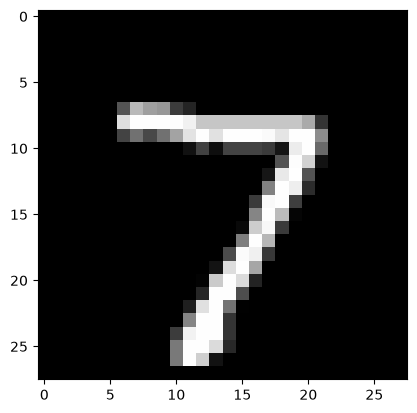

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
Predicted: 7
Actual: 7


In [7]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import *

(X_train,y_train),(X_test,y_test) = tf.keras.datasets.mnist.load_data()
X_train,X_test = X_train[...,None]/255,X_test[...,None]/255

model = Sequential([
    Conv2D(8,3,activation='relu'),
    MaxPooling2D(2), 
    Flatten(),
    Dense(32,activation='relu'),
    Dense(10,activation='softmax')])

model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])
history = model.fit(X_train,y_train,epochs=3,validation_data=(X_test,y_test))

plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.legend(['Train','Test'])
plt.show()

plt.imshow(X_test[0].squeeze(),cmap='gray')
plt.show()
print("Predicted:",np.argmax(model.predict(X_test[:1])))
print("Actual:",y_test[0])